# rel-hm / item-sales — Pondération des hops (hop decay)

> **Variante de `hm_gnn.ipynb`** : on teste un *decay* fixe par hop —
> le 2ème round de message passing est multiplié par un scalaire < 1.0
> pour réduire son poids par rapport au 1er hop.
> Tout le reste (données, graphe, harness) est inchangé.

Décays testés : `None` (baseline, [1.0,1.0]) | `[1.0, 0.8]` | `[1.0, 0.5]` | `[1.0, 0.2]`  
3 seeds × 4 configs = **12 runs** (≈ 15 min sur P100).


In [1]:
#!pip install torch torch_geometric relbench -q

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.data import HeteroData
from torch_geometric.nn import HeteroConv, SAGEConv
import pandas as pd, numpy as np
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from relbench.tasks import get_task

print(f"PyTorch : {torch.__version__}")
import torch_geometric; print(f"PyG     : {torch_geometric.__version__}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device  : {device}")

PyTorch : 2.7.1+cu118
PyG     : 2.8.0
Device  : cuda


## 1. Chargement des données

In [3]:
print("Chargement rel-hm...")
task = get_task('rel-hm', 'item-sales', download=False)
db   = task.dataset.get_db()

articles_df      = db.table_dict['article'].df.copy()
customers_df     = db.table_dict['customer'].df.copy()
transactions_df  = db.table_dict['transactions'].df.copy()

train_tbl = task.get_table("train")
val_tbl   = task.get_table("val")
test_tbl  = task.get_table("test")

VAL_TIMESTAMP  = val_tbl.df['timestamp'].iloc[0]
TEST_TIMESTAMP = test_tbl.df['timestamp'].iloc[0]

print(f"Articles     : {len(articles_df):,}")
print(f"Customers    : {len(customers_df):,}")
print(f"Transactions : {len(transactions_df):,}")
print(f"Val  : {VAL_TIMESTAMP.date()} | Test : {TEST_TIMESTAMP.date()}")

Chargement rel-hm...
Loading Database object from /home/infres/sryszfeld-24/.cache/relbench/rel-hm/db...


Done in 2.34 seconds.


Articles     : 105,542
Customers    : 1,371,980
Transactions : 15,187,287
Val  : 2020-09-07 | Test : 2020-09-14


## 2. Encodage des nœuds

In [4]:
# ── Articles (105k nœuds) ──────────────────────────────────────────────────
ART_CAT = ['product_type_name', 'product_group_name', 'colour_group_name',
           'department_name', 'garment_group_name']

# fillna('missing') AVANT l'encodage : OrdinalEncoder réémet np.nan pour les
# valeurs manquantes (param encoded_missing_value=np.nan par défaut) → features
# NaN → message passing NaN → loss NaN → RMSE inf. On bouche la source ici.
enc_art = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
art_cat_enc = enc_art.fit_transform(articles_df[ART_CAT].fillna('missing').astype(str)).astype(np.float32)
# Standardisation des codes ordinaux (échelle homogène en entrée des Linear)
art_cat_enc = (art_cat_enc - art_cat_enc.mean(0)) / (art_cat_enc.std(0) + 1e-8)

art_map = {aid: i for i, aid in enumerate(articles_df['article_id'].values)}
N_ART = len(art_map)

# ── Features HISTORIQUES par article (le signal qui manquait) ────────────────
# Diagnostic : sans historique de ventes, le GNN "collapse" (corr(pred,true)=0.05,
# il prédit ~une constante) alors que LightGBM atteint R²=0.61 GRÂCE à ses lags.
# On injecte l'équivalent graph-natif : les ventes passées agrégées par article,
# calculées STRICTEMENT sur la période train (< val) → aucune fuite vers la val.
# Corrélations mesurées avec sales(val) : lag1=0.77, moy. 4 dern. sem.=0.68,
# moy. historique=0.28 — d'où l'effet attendu sur le collapse.
_panel = train_tbl.df
_weeks = np.sort(_panel['timestamp'].unique())
_lag1  = _panel[_panel['timestamp'] == _weeks[-1]].set_index('article_id')['sales']
_rec4  = _panel[_panel['timestamp'].isin(_weeks[-4:])].groupby('article_id')['sales'].mean()
_hmean = _panel.groupby('article_id')['sales'].mean()
_hmax  = _panel.groupby('article_id')['sales'].max()

art_hist = np.zeros((N_ART, 4), dtype=np.float32)
for j, s in enumerate([_lag1, _rec4, _hmean, _hmax]):
    idx = np.fromiter((art_map[a] for a in s.index), dtype=np.int64, count=len(s))
    art_hist[idx, j] = np.log1p(s.values.astype(np.float32))   # log1p : ventes très skewées
art_hist = (art_hist - art_hist.mean(0)) / (art_hist.std(0) + 1e-8)

# Deux jeux de features article, pour l'ablation H1 (autocorrélation) :
#   art_feat        = catégorielles + historique de ventes (lags agrégés)  → modèle complet
#   art_feat_nohist = catégorielles SEULES                                  → "sans autorégression"
# Le harness choisit l'un ou l'autre via use_art_hist ; la skip connection (qui
# réinjecte les features brutes dans la tête) suit automatiquement le choix.
art_feat        = torch.tensor(np.hstack([art_cat_enc, art_hist]), dtype=torch.float32)  # [N_art, 9]
art_feat_nohist = torch.tensor(art_cat_enc,                        dtype=torch.float32)  # [N_art, 5]
assert torch.isfinite(art_feat).all() and torch.isfinite(art_feat_nohist).all(), 'art_feat NaN/inf'

# ── Customers (1.37M nœuds) ───────────────────────────────────────────────
# Idem articles : les colonnes customer ont beaucoup de NaN (club_member_status,
# fashion_news_frequency, age) → fillna obligatoire avant l'encodage.
CUST_CAT = ['club_member_status', 'fashion_news_frequency']

enc_cust = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
cust_cat_enc = enc_cust.fit_transform(customers_df[CUST_CAT].fillna('missing').astype(str)).astype(np.float32)
cust_cat_enc = (cust_cat_enc - cust_cat_enc.mean(0)) / (cust_cat_enc.std(0) + 1e-8)
cust_age     = customers_df['age'].fillna(customers_df['age'].median()).values.reshape(-1, 1).astype(np.float32)
cust_age     = (cust_age - cust_age.mean()) / (cust_age.std() + 1e-8)
cust_feat    = torch.tensor(np.hstack([cust_cat_enc, cust_age]), dtype=torch.float32)  # [N_cust, 3]
assert torch.isfinite(cust_feat).all(), 'cust_feat contient des NaN/inf'

cust_map = {cid: i for i, cid in enumerate(customers_df['customer_id'].values)}
N_CUST = len(cust_map)

print(f"Article features  : {tuple(art_feat.shape)} complet | {tuple(art_feat_nohist.shape)} sans historique")
print(f"Customer features : {tuple(cust_feat.shape)}")


Article features  : (105542, 9) complet | (105542, 5) sans historique
Customer features : (1371980, 3)


## 3. Construction du graphe (transactions de la période train uniquement)

In [5]:
# Transactions avant VAL_TIMESTAMP uniquement (pas de fuite)
tx_train = transactions_df[transactions_df['t_dat'] < VAL_TIMESTAMP].copy()
print(f"Transactions train : {len(tx_train):,}")

# Agregation -> aretes uniques (customer, article), AVANT sparsification.
edges_full = (tx_train.groupby(['customer_id', 'article_id'])
                      .size().reset_index(name='n_tx'))
edges_full['c_idx'] = edges_full['customer_id'].map(cust_map)
edges_full['a_idx'] = edges_full['article_id'].map(art_map)
edges_full = edges_full.dropna(subset=['c_idx', 'a_idx'])
edges_full['c_idx'] = edges_full['c_idx'].astype(int)
edges_full['a_idx'] = edges_full['a_idx'].astype(int)
edges_full = edges_full[['c_idx', 'a_idx']].reset_index(drop=True)
print(f"Aretes uniques (customer, article) : {len(edges_full):,}")

DEFAULT_MAX_CUST_PER_ART = 30

def build_graph(max_cust_per_art=DEFAULT_MAX_CUST_PER_ART, seed=0, art_x=None, cust_x=None):
    """Construit le HeteroData en plafonnant a K acheteurs/article.

    art_x  : features article (defaut = art_feat global)
    cust_x : features customer (defaut = cust_feat global) ;
             passer torch.zeros(N_CUST, 0) pour la variante B (cust vide).
    """
    if art_x  is None: art_x  = art_feat
    if cust_x is None: cust_x = cust_feat
    e = edges_full.sample(frac=1.0, random_state=seed)
    e = e.assign(_rank=e.groupby('a_idx').cumcount())
    e = e[e['_rank'] < max_cust_per_art]
    c_src = torch.tensor(e['c_idx'].values, dtype=torch.long)
    a_dst = torch.tensor(e['a_idx'].values, dtype=torch.long)
    g = HeteroData()
    g['article'].x  = art_x
    g['customer'].x = cust_x
    g['customer', 'buys',     'article'].edge_index = torch.stack([c_src, a_dst])
    g['article',  'rev_buys', 'customer'].edge_index = torch.stack([a_dst, c_src])
    return g, len(e)

# Sanity : graphe par defaut (K=30, seed=0, features article completes)
_g, _ne = build_graph()
print(f"Graphe defaut (K={DEFAULT_MAX_CUST_PER_ART}, seed=0) : {_ne:,} aretes | "
      f"{edges_full['a_idx'].nunique():,}/{N_ART:,} articles couverts")
print(_g)
del _g


Transactions train : 14,883,771


Aretes uniques (customer, article) : 12,860,789


Graphe defaut (K=30, seed=0) : 1,310,548 aretes | 70,131/105,542 articles couverts
HeteroData(
  article={ x=[105542, 9] },
  customer={ x=[1371980, 3] },
  (customer, buys, article)={ edge_index=[2, 1310548] },
  (article, rev_buys, customer)={ edge_index=[2, 1310548] }
)


## 4. Préparation des tenseurs cibles

In [6]:
# ── Panel hebdomadaire des ventes (TRAIN uniquement → aucune fuite) ──────────
# Le signal dominant est autorégressif : sales(t) ≈ sales(t-1). LightGBM gagne
# parce qu'il lit lag1/lag2/ma4 BRUTS. On reproduit ça ici : pour chaque ligne
# (article, semaine), on calcule les ventes des semaines PRÉCÉDENTES relatives à
# cette ligne. Brutes (pas de log1p) → relation linéaire avec la cible → la tête
# peut retrouver la persistance puis l'améliorer. Aucune fuite : la val (semaine
# juste après la fin du train) n'utilise que des semaines train.
_pan   = train_tbl.df[['article_id', 'timestamp', 'sales']].copy()
_wk    = np.sort(_pan['timestamp'].unique())
_n_wk  = len(_wk)
_wkmap = {w: i for i, w in enumerate(_wk)}
_wkmap[VAL_TIMESTAMP]  = _n_wk        # val  = 1 semaine après la fin du train
_wkmap[TEST_TIMESTAMP] = _n_wk + 1    # test = 2 semaines après

# matrice [article × semaine] des ventes (0 si pas de vente), tous les articles
_sales_mat = (_pan.assign(w=_pan['timestamp'].map(_wkmap))
                  .pivot_table(index='article_id', columns='w', values='sales',
                               aggfunc='sum', fill_value=0.0)
                  .reindex(index=articles_df['article_id'].values, fill_value=0.0)
                  .reindex(columns=range(_n_wk), fill_value=0.0)
                  .values.astype(np.float32))
_artrow = {a: i for i, a in enumerate(articles_df['article_id'].values)}
# padding (4 zéros à gauche, 2 à droite) → lags hors série = 0, pas d'index error
_PAD    = 4
_padmat = np.concatenate(
    [np.zeros((_sales_mat.shape[0], _PAD), np.float32), _sales_mat,
     np.zeros((_sales_mat.shape[0], 2), np.float32)], axis=1)

def _lag_feats(article_ids, week_idx):
    """lag1, lag2, ma4 BRUTS par ligne — ventes des semaines précédentes."""
    r = pd.Series(article_ids).map(_artrow).fillna(-1).astype(int).values
    w = np.asarray(week_idx, dtype=int)
    valid = r >= 0
    rr = np.where(valid, r, 0)
    c  = _PAD + w                       # colonne de la semaine courante
    lag1 = _padmat[rr, c - 1]
    lag2 = _padmat[rr, c - 2]
    ma4  = (_padmat[rr, c-1] + _padmat[rr, c-2] + _padmat[rr, c-3] + _padmat[rr, c-4]) / 4.0
    out = np.stack([lag1, lag2, ma4], axis=1)
    out[~valid] = 0.0
    return out.astype(np.float32)


def prepare(df_task, art_map, temporal_scaler=None, fit_scaler=False):
    df = df_task.copy()
    df['a_idx'] = df['article_id'].map(art_map)
    df = df.dropna(subset=['a_idx'])
    df['a_idx'] = df['a_idx'].astype(int)

    w_idx = df['timestamp'].map(_wkmap).astype(int).values
    time_raw = np.column_stack([
        df['timestamp'].dt.isocalendar().week.astype(float).values,
        df['timestamp'].dt.month.values.astype(float),
        _lag_feats(df['article_id'].values, w_idx),     # lag1, lag2, ma4 (bruts)
    ]).astype(np.float32)

    if fit_scaler:
        temporal_scaler = StandardScaler()
        time_norm = temporal_scaler.fit_transform(time_raw)
    else:
        time_norm = temporal_scaler.transform(time_raw)

    ai = torch.tensor(df['a_idx'].values, dtype=torch.long)
    tf = torch.tensor(time_norm,          dtype=torch.float32)

    # test_tbl n'a pas de colonne 'sales' (labels cachés — leaderboard RelBench)
    if 'sales' in df.columns:
        yt = torch.tensor(df['sales'].values, dtype=torch.float32)
    else:
        yt = None

    return ai, tf, yt, temporal_scaler, df

ai_train, tf_train, y_train, scaler_t, df_tr = prepare(train_tbl.df, art_map, fit_scaler=True)
ai_val,   tf_val,   y_val,   _,        df_vl = prepare(val_tbl.df,   art_map, scaler_t)
ai_test,  tf_test,  y_test,  _,        df_ts = prepare(test_tbl.df,  art_map, scaler_t)
# y_test is None — labels non disponibles, évaluation finale sur val_tbl

print(f"Train tensors : {ai_train.shape}  tf={tuple(tf_train.shape)}  y={y_train.shape}")
print(f"Val   tensors : {ai_val.shape}    tf={tuple(tf_val.shape)}  y={y_val.shape}")
print(f"Features temporelles : semaine, mois, lag1, lag2, ma4")


Train tensors : torch.Size([5488184])  tf=(5488184, 5)  y=torch.Size([5488184])
Val   tensors : torch.Size([105542])    tf=(105542, 5)  y=torch.Size([105542])
Features temporelles : semaine, mois, lag1, lag2, ma4


## 5. Modèle HeteroGraphSAGE

In [7]:
class HeteroSAGE(nn.Module):
    """HeteroSAGE avec pondération optionnelle des hops (hop_decay).

    hop_decay : liste de scalaires [w1, w2, ...], un par couche SAGEConv.
    La sortie de la couche i est multipliee par hop_decay[i] avant d'etre
    passee a la couche suivante. Defaut None -> [1.0, 1.0, ...] (original).

    Intuition : les voisins directs (hop 1) portent plus de signal que les
    voisins de voisins (hop 2) ; le decay force ce biais de proximite.
    """
    def __init__(self, in_art, in_cust, emb_dim=32, hidden=64, n_temporal=5,
                 n_layers=2, aggr='mean', hop_decay=None):
        super().__init__()
        self.in_art   = in_art
        self.n_layers = n_layers

        if hop_decay is None:
            hop_decay = [1.0] * n_layers
        if len(hop_decay) != n_layers:
            raise ValueError(f"hop_decay doit avoir {n_layers} elements, recu {len(hop_decay)}")
        self.hop_decay = hop_decay

        self.art_emb  = nn.Embedding(N_ART,  emb_dim)
        self.cust_emb = nn.Embedding(N_CUST, emb_dim // 2)
        nn.init.normal_(self.art_emb.weight,  std=0.01)
        nn.init.normal_(self.cust_emb.weight, std=0.01)

        self.proj = nn.ModuleDict({
            'article' : nn.Linear(in_art  + emb_dim,      hidden),
            'customer': nn.Linear(in_cust + emb_dim // 2, hidden),
        })
        self.convs = nn.ModuleList([
            HeteroConv({
                ('customer', 'buys',     'article') : SAGEConv(hidden, hidden, aggr=aggr),
                ('article',  'rev_buys', 'customer'): SAGEConv(hidden, hidden, aggr=aggr),
            }, aggr='sum')
            for _ in range(n_layers)
        ])
        self.head = nn.Sequential(
            nn.Linear(hidden + in_art + n_temporal, hidden),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden, 1),
        )

    def encode(self, x_dict, edge_index_dict):
        art_ids  = torch.arange(N_ART,  device=x_dict['article'].device)
        cust_ids = torch.arange(N_CUST, device=x_dict['customer'].device)
        x_art  = torch.cat([x_dict['article'],  self.art_emb(art_ids)],   dim=1)
        x_cust = torch.cat([x_dict['customer'], self.cust_emb(cust_ids)], dim=1)
        h = {
            'article' : F.relu(self.proj['article'](x_art)),
            'customer': F.relu(self.proj['customer'](x_cust)),
        }
        for i, conv in enumerate(self.convs):
            h_new = {k: F.relu(v) for k, v in conv(h, edge_index_dict).items()}
            d = self.hop_decay[i]
            h = {k: d * v for k, v in h_new.items()} if d != 1.0 else h_new
        return h

    def forward(self, x_dict, edge_index_dict, art_idx, time_feats):
        h   = self.encode(x_dict, edge_index_dict)
        emb = h['article'][art_idx]
        raw = x_dict['article'][art_idx]        # skip : lag1 & co. en direct
        return self.head(torch.cat([emb, raw, time_feats], dim=1)).squeeze(1)

print("Modele HeteroSAGE (avec hop_decay) defini.")


Modele HeteroSAGE (avec hop_decay) defini.


## 5bis. Harness d'ablation — `train_and_eval(...)`

Fonction unique qui entraîne **un** HeteroSAGE et renvoie ses métriques sur le val officiel.
Toutes les expériences passent par elle → comparaisons **à modèle fixe**, seul l'argument ciblé varie :

| Argument | Hypothèse | Effet |
|---|---|---|
| `n_layers` ∈ {0,1,2} | **H2** | profondeur = quantité de structure (0 = aucune) |
| `use_temporal` | **H1** | active/coupe les lags par ligne (calendrier + lag1/lag2/ma4) |
| `use_art_hist` | **H1** | active/coupe l'historique de ventes agrégé par article |
| `seed` | reproductibilité | init modèle **et** tirage des acheteurs → moyennes ± écart-types |
| `max_cust_per_art` | densité | nombre d'acheteurs gardés par article (mémoire/structure) |


In [8]:
import json, time, gc, random
from pathlib import Path

RESULTS_DIR = Path('../reports/ablations'); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def train_and_eval(n_layers=2, use_temporal=True, use_art_hist=True, seed=0,
                   max_cust_per_art=DEFAULT_MAX_CUST_PER_ART, aggr='mean',
                   hop_decay=None,
                   art_feat_override=None, cust_feat_override=None,
                   epochs=200, patience=20, lr=5e-4, wd=0.0,
                   emb_dim=32, hidden=64, return_model=False, verbose=False):
    """Entraine + evalue UN HeteroSAGE -> dict de metriques (val officiel RelBench).

    hop_decay         : None (baseline) ou liste [w1, w2] pour ponderer les hops.
    art_feat_override : remplace art_feat (ou art_feat_nohist) dans le graphe.
    cust_feat_override: remplace cust_feat dans le graphe (ex: zeros pour variante B).
    """
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    set_seed(seed)
    t0 = time.time()

    # Features article
    if art_feat_override is not None:
        art_x  = art_feat_override
    else:
        art_x  = art_feat if use_art_hist else art_feat_nohist
    in_art = art_x.shape[1]

    g, n_edges = build_graph(max_cust_per_art, seed, art_x, cust_x=cust_feat_override)
    g = g.to(device)
    x_dict, edge_index_dict = g.x_dict, g.edge_index_dict

    tf_tr = tf_train if use_temporal else tf_train[:, :0]
    tf_vl = tf_val   if use_temporal else tf_val[:, :0]
    n_temporal = tf_tr.shape[1]

    in_cust = (cust_feat_override if cust_feat_override is not None else cust_feat).shape[1]

    model = HeteroSAGE(in_art=in_art, in_cust=in_cust,
                       emb_dim=emb_dim, hidden=hidden,
                       n_temporal=n_temporal, n_layers=n_layers, aggr=aggr,
                       hop_decay=hop_decay).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)

    ai_tr_d, tf_tr_d = ai_train.to(device), tf_tr.to(device)
    ai_vl_d, tf_vl_d = ai_val.to(device),   tf_vl.to(device)
    y_tr_d = y_train.clamp(min=0).to(device)
    y_vl_d = y_val.clamp(min=0).to(device)

    best_rmse, ctr, epoch = float('inf'), 0, 0
    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        pred = model(x_dict, edge_index_dict, ai_tr_d, tf_tr_d)
        loss = F.mse_loss(pred, y_tr_d)
        if not torch.isfinite(loss):
            if verbose: print(f"  epoch {epoch}: loss non finie -- arret.")
            break
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        opt.step()

        model.eval()
        with torch.no_grad():
            vp = model(x_dict, edge_index_dict, ai_vl_d, tf_vl_d).clamp(min=0)
            vr = torch.sqrt(F.mse_loss(vp, y_vl_d)).item()
        if np.isfinite(vr) and vr < best_rmse:
            best_rmse, ctr = vr, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            ctr += 1
        if verbose and (epoch == 1 or epoch % 20 == 0):
            print(f"  epoch {epoch:3d} | MSE {loss.item():.4f} | Val RMSE {vr:.4f}")
        if ctr >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        yp = model(x_dict, edge_index_dict, ai_vl_d, tf_vl_d).clamp(min=0).cpu().numpy()
    yt = y_val.numpy()

    res = {
        'n_layers': n_layers, 'use_temporal': use_temporal, 'use_art_hist': use_art_hist,
        'aggr': aggr, 'hop_decay': str(hop_decay),
        'art_feat_dim': int(in_art), 'cust_feat_dim': int(in_cust),
        'seed': seed, 'max_cust_per_art': max_cust_per_art, 'n_edges': int(n_edges),
        'mae':  float(mean_absolute_error(yt, yp)),
        'rmse': float(np.sqrt(mean_squared_error(yt, yp))),
        'r2':   float(r2_score(yt, yp)),
        'std_pred': float(yp.std()), 'std_true': float(yt.std()),
        'corr': float(np.corrcoef(yp, yt)[0, 1]),
        'best_val_rmse': float(best_rmse), 'epochs_ran': int(epoch),
        'sec': round(time.time() - t0, 1),
    }
    if return_model:
        res['_model'], res['_y_pred_val'] = model, yp
    else:
        del model
    del g, x_dict, edge_index_dict
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return res

print("Harness pret : train_and_eval(..., hop_decay, art_feat_override, cust_feat_override)")
print(f"Resultats -> {RESULTS_DIR.resolve()}")


Harness pret : train_and_eval(..., hop_decay, art_feat_override, cust_feat_override)
Resultats -> /home/infres/sryszfeld-24/beyond-flat-tables/reports/ablations


## 6. Entraînement

In [9]:
# ── Baseline = modèle COMPLET (2 sauts, temporel + historique) via le harness ──
# Reproduit le ~0.44 RMSE de référence et expose `model` / `y_pred_gnn` pour les
# cellules d'évaluation et de diagnostic ci-dessous. Les ablations (H1/H2) sont
# lancées plus bas, toutes via le même train_and_eval → comparaison à modèle fixe.
baseline = train_and_eval(n_layers=2, use_temporal=True, use_art_hist=True,
                          seed=0, epochs=200, patience=20,
                          return_model=True, verbose=True)

model      = baseline['_model']        # réutilisé par les cellules 7 (éval) et suivantes
y_pred_gnn = baseline['_y_pred_val']

print(f"\nBaseline (2 sauts, temporel+hist) | "
      f"RMSE {baseline['rmse']:.4f} | MAE {baseline['mae']:.4f} | R² {baseline['r2']:.4f} | "
      f"corr {baseline['corr']:.3f} | {baseline['epochs_ran']} epochs | {baseline['sec']}s")


  epoch   1 | MSE 0.2549 | Val RMSE 0.6511


  epoch  20 | MSE 0.1804 | Val RMSE 0.5659


  epoch  40 | MSE 0.1309 | Val RMSE 0.5161


  epoch  60 | MSE 0.1114 | Val RMSE 0.4699


  epoch  80 | MSE 0.1039 | Val RMSE 0.4600


...

  epoch 140 | MSE 0.0945 | Val RMSE 0.4442


  epoch 160 | MSE 0.0922 | Val RMSE 0.4422


  epoch 180 | MSE 0.0904 | Val RMSE 0.4411


  epoch 200 | MSE 0.0892 | Val RMSE 0.4405



Baseline (2 sauts, temporel+hist) | RMSE 0.4403 | MAE 0.0598 | R² 0.5580 | corr 0.748 | 200 epochs | 103.0s


## 7. Évaluation & comparaison

In [10]:
# Note : test_tbl n'a pas de labels → évaluation finale sur val officiel RelBench.
# y_pred_gnn provient du harness (cellule baseline) : le graphe y est construit puis
# libéré en interne, on ne le reconstruit donc pas ici. Déjà clampé à 0.
y_pred_gnn = np.clip(y_pred_gnn, 0, None)
y_true_np  = y_val.numpy()

mae_gnn  = mean_absolute_error(y_true_np, y_pred_gnn)
rmse_gnn = np.sqrt(mean_squared_error(y_true_np, y_pred_gnn))
r2_gnn   = r2_score(y_true_np, y_pred_gnn)

# Baseline persistance : lag1 = ventes de la dernière semaine du train par article
last_train_ts = train_tbl.df['timestamp'].max()
last_week = train_tbl.df[train_tbl.df['timestamp'] == last_train_ts]
lag1_per_art = last_week.set_index('article_id')['sales']
lag1_arr = df_vl['article_id'].map(lag1_per_art).fillna(0).values

mae_p  = mean_absolute_error(y_true_np, lag1_arr)
rmse_p = np.sqrt(mean_squared_error(y_true_np, lag1_arr))
r2_p   = r2_score(y_true_np, lag1_arr)

print(f"Évaluation sur val officiel RelBench (timestamp = {VAL_TIMESTAMP.date()})")
print(f"{'Métrique':<10} {'HeteroSAGE':>14} {'LightGBM':>12} {'Persistance':>14}")
print(f"{'-'*55}")
print(f"{'MAE':<10} {mae_gnn:>14.4f} {'0.0503':>12} {mae_p:>14.4f}")
print(f"{'RMSE':<10} {rmse_gnn:>14.4f} {'0.4121':>12} {rmse_p:>14.4f}")
print(f"{'R²':<10} {r2_gnn:>14.4f} {'0.6129':>12} {r2_p:>14.4f}")


Évaluation sur val officiel RelBench (timestamp = 2020-09-07)
Métrique       HeteroSAGE     LightGBM    Persistance
-------------------------------------------------------
MAE                0.0598       0.0503         0.0472
RMSE               0.4403       0.4121         0.4323
R²                 0.5580       0.6129         0.5739


In [11]:
# ── Diagnostic : le modèle a-t-il appris, ou prédit-il ~une constante ? ──────
std_true = y_true_np.std()

print("=== 1. Signature d'un 'collapse' (prédiction quasi constante) ===")
print(f"std(y_true)        : {std_true:.4f}")
print(f"std(y_pred GNN)    : {y_pred_gnn.std():.4f}   <- si << std(y_true) => collapse")
print(f"RMSE GNN           : {rmse_gnn:.4f}")
print(f"RMSE / std(y_true) : {rmse_gnn/std_true:.3f}   (~1.0 <=> R²~0 <=> prédit la moyenne)")
print()
print("=== 2. Étendue des prédictions vs réel ===")
print(f"pred  min/mean/max : {y_pred_gnn.min():.3f} / {y_pred_gnn.mean():.3f} / {y_pred_gnn.max():.3f}")
print(f"true  min/mean/max : {y_true_np.min():.3f} / {y_true_np.mean():.3f} / {y_true_np.max():.3f}")
print(f"corr(pred, true)   : {np.corrcoef(y_pred_gnn, y_true_np)[0,1]:.4f}   (0 => aucun lien)")
print()
print("=== 3. Le modèle distingue-t-il vendeurs / non-vendeurs ? ===")
mask0 = y_true_np == 0
print(f"part de zéros dans y_true : {mask0.mean()*100:.1f}%")
print(f"pred moyenne | y == 0     : {y_pred_gnn[mask0].mean():.4f}")
print(f"pred moyenne | y >  0     : {y_pred_gnn[~mask0].mean():.4f}   <- si ≈ égal => ne discrimine pas")


=== 1. Signature d'un 'collapse' (prédiction quasi constante) ===
std(y_true)        : 0.6623
std(y_pred GNN)    : 0.4684   <- si << std(y_true) => collapse
RMSE GNN           : 0.4403
RMSE / std(y_true) : 0.665   (~1.0 <=> R²~0 <=> prédit la moyenne)

=== 2. Étendue des prédictions vs réel ===
pred  min/mean/max : 0.000 / 0.085 / 20.820
true  min/mean/max : 0.000 / 0.086 / 40.365
corr(pred, true)   : 0.7481   (0 => aucun lien)

=== 3. Le modèle distingue-t-il vendeurs / non-vendeurs ? ===
part de zéros dans y_true : 82.3%
pred moyenne | y == 0     : 0.0143
pred moyenne | y >  0     : 0.4122   <- si ≈ égal => ne discrimine pas


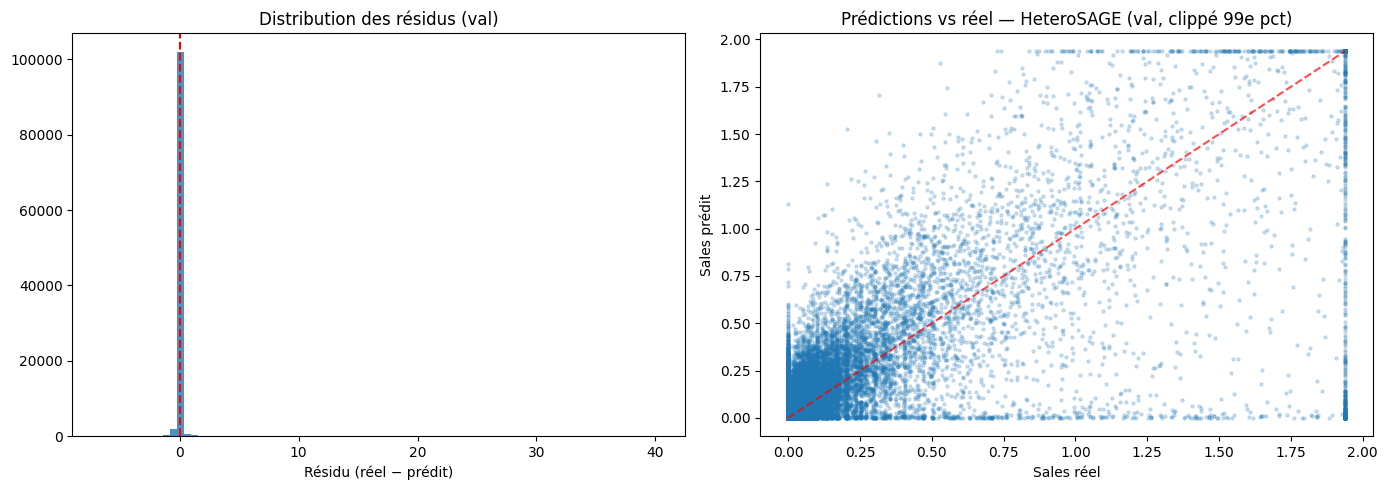

In [12]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals = y_true_np - y_pred_gnn
axes[0].hist(residuals, bins=80, edgecolor='none', alpha=0.8)
axes[0].axvline(0, color='red', lw=1.5, ls='--')
axes[0].set_title('Distribution des résidus (val)')
axes[0].set_xlabel('Résidu (réel − prédit)')

clip = np.percentile(y_true_np, 99)
axes[1].scatter(np.clip(y_true_np, 0, clip), np.clip(y_pred_gnn, 0, clip), alpha=0.2, s=5)
axes[1].plot([0, clip], [0, clip], 'r--', alpha=0.7)
axes[1].set_xlabel('Sales réel'); axes[1].set_ylabel('Sales prédit')
axes[1].set_title('Prédictions vs réel — HeteroSAGE (val, clippé 99e pct)')
plt.tight_layout(); plt.show()


## Ablation hop decay

On teste 4 configurations de pondération du 2ème hop :
- `None` → [1.0, 1.0] (baseline, comportement original)
- `[1.0, 0.8]` → léger discount
- `[1.0, 0.5]` → discount modéré
- `[1.0, 0.2]` → fort discount (quasi-suppression du 2ème hop)

3 seeds × 4 configs = 12 runs. Toujours 2 sauts, features complètes.


In [13]:
SEEDS  = [0, 1, 2]
DECAYS = [None, [1.0, 0.8], [1.0, 0.5], [1.0, 0.2]]

decay_runs = []
for decay in DECAYS:
    for seed in SEEDS:
        label = str(decay) if decay is not None else "None=[1.0,1.0]"
        r = train_and_eval(n_layers=2, use_temporal=True, use_art_hist=True,
                           seed=seed, hop_decay=decay,
                           epochs=200, patience=20, verbose=False)
        decay_runs.append(r)
        print(f"decay={label:<20} seed={seed} | "
              f"RMSE {r['rmse']:.4f} | R2 {r['r2']:.4f} | "
              f"corr {r['corr']:.3f} | {r['epochs_ran']}ep {r['sec']}s")

# Sauvegarde
out_path = RESULTS_DIR / 'hop_decay_ablation.json'
with open(out_path, 'w') as f:
    json.dump(decay_runs, f, indent=2)
print(f"\nSauvegarde -> {out_path}")


decay=None=[1.0,1.0]       seed=0 | RMSE 0.4403 | R2 0.5580 | corr 0.748 | 200ep 102.5s


decay=None=[1.0,1.0]       seed=1 | RMSE 0.4358 | R2 0.5671 | corr 0.754 | 200ep 101.5s


decay=None=[1.0,1.0]       seed=2 | RMSE 0.4369 | R2 0.5648 | corr 0.753 | 200ep 102.7s


decay=[1.0, 0.8]           seed=0 | RMSE 0.4401 | R2 0.5585 | corr 0.748 | 200ep 103.7s


decay=[1.0, 0.8]           seed=1 | RMSE 0.4353 | R2 0.5680 | corr 0.755 | 200ep 101.8s


...

decay=[1.0, 0.5]           seed=1 | RMSE 0.4348 | R2 0.5690 | corr 0.755 | 200ep 101.3s


decay=[1.0, 0.5]           seed=2 | RMSE 0.4356 | R2 0.5674 | corr 0.754 | 200ep 104.5s


decay=[1.0, 0.2]           seed=0 | RMSE 0.4386 | R2 0.5613 | corr 0.750 | 200ep 102.7s


decay=[1.0, 0.2]           seed=1 | RMSE 0.4326 | R2 0.5733 | corr 0.758 | 200ep 104.7s


decay=[1.0, 0.2]           seed=2 | RMSE 0.4350 | R2 0.5686 | corr 0.755 | 200ep 103.6s

Sauvegarde -> ../reports/ablations/hop_decay_ablation.json


## Synthese des resultats

In [14]:
import pandas as pd, numpy as np, json

with open(RESULTS_DIR / 'hop_decay_ablation.json') as f:
    runs = json.load(f)

df = pd.DataFrame(runs)
df['decay_label'] = df['hop_decay'].apply(
    lambda x: 'baseline [1,1]' if x == 'None' else x
)

agg = df.groupby('decay_label')[['rmse', 'mae', 'r2', 'corr']].agg(['mean', 'std'])
agg.columns = ['_'.join(c) for c in agg.columns]

# Ordre logique : baseline d'abord, puis decay croissant
order = ['baseline [1,1]', '[1.0, 0.8]', '[1.0, 0.5]', '[1.0, 0.2]']
agg = agg.reindex([o for o in order if o in agg.index])

print("=== Ablation hop decay — val officiel, moyenne +/- std sur 3 seeds ===\n")
print(f"{'Config':<22} {'RMSE':>10} {'R2':>10} {'corr':>10}")
print('-' * 55)
for idx, row in agg.iterrows():
    print(f"{idx:<22} {row['rmse_mean']:.4f}±{row['rmse_std']:.4f}  "
          f"{row['r2_mean']:.4f}±{row['r2_std']:.4f}  "
          f"{row['corr_mean']:.3f}±{row['corr_std']:.3f}")

print()
baseline_r2 = agg.loc['baseline [1,1]', 'r2_mean'] if 'baseline [1,1]' in agg.index else float('nan')
print(f"Baseline R2 (reference) : {baseline_r2:.4f}")
for idx, row in agg.iterrows():
    if idx != 'baseline [1,1]':
        delta = row['r2_mean'] - baseline_r2
        print(f"  delta R2 vs baseline [{idx}] : {delta:+.4f}")


=== Ablation hop decay — val officiel, moyenne +/- std sur 3 seeds ===

Config                       RMSE         R2       corr
-------------------------------------------------------
baseline [1,1]         0.4377±0.0024  0.5633±0.0047  0.752±0.003
[1.0, 0.8]             0.4373±0.0025  0.5640±0.0050  0.752±0.003
[1.0, 0.5]             0.4369±0.0029  0.5648±0.0059  0.753±0.004
[1.0, 0.2]             0.4354±0.0030  0.5677±0.0060  0.754±0.004

Baseline R2 (reference) : 0.5633
  delta R2 vs baseline [[1.0, 0.8]] : +0.0007
  delta R2 vs baseline [[1.0, 0.5]] : +0.0016
  delta R2 vs baseline [[1.0, 0.2]] : +0.0045


## Ablation features de noeuds (variantes A / B / C)

Idee : retirer les features bruyantes des noeuds (pas en ajouter) pour donner
au GNN un signal plus propre lors du message passing.

- **Variante A** : article = seulement les 4 lags (supprime les 5 categoriques)
- **Variante B** : customer = aucune feature (seulement l'embedding nn.Embedding)
- **Variante C** : A + B combines
- **Baseline** : full (art 9 dims + cust 3 dims, comportement original)

Argument methodologique : on ne rajoute pas de features (LightGBM n'en
beneficierait pas), on en retire — on teste si les categoriques sont du bruit.

3 seeds x 4 configs = **12 runs** (2 sauts, features temporelles completes).


In [15]:
# ── Definition des variantes de features ────────────────────────────────────
# art_feat = [art_cat_enc (5 dims) | art_hist (4 dims lags)]
# Variante A : supprimer les 5 categoriques, ne garder que les 4 lags historiques
art_feat_lagsonly = art_feat[:, 5:]   # [N_art, 4]

# Variante B : pas de features customer (seulement l'embedding d'identite nn.Embedding)
cust_feat_empty = torch.zeros(N_CUST, 0, dtype=torch.float32)  # [N_cust, 0]

print(f"Variante A (art lags only) : {tuple(art_feat_lagsonly.shape)}")
print(f"Variante B (cust vide)     : {tuple(cust_feat_empty.shape)}")
print(f"Baseline (full)            : art {tuple(art_feat.shape)} | cust {tuple(cust_feat.shape)}")

# Note : cust_feat_empty de taille [N_cust, 0] est valide en PyTorch ;
# torch.cat([zeros(N,0), emb(N,16)]) = emb(N,16) -> Linear(16, hidden) OK.
# On le verifie :
_test = torch.cat([cust_feat_empty[:3], torch.randn(3, 16)], dim=1)
assert _test.shape == (3, 16), f"Inattendu : {_test.shape}"
print("Verification torch.cat([..., 0], emb) : OK")


Variante A (art lags only) : (105542, 4)
Variante B (cust vide)     : (1371980, 0)
Baseline (full)            : art (105542, 9) | cust (1371980, 3)
Verification torch.cat([..., 0], emb) : OK


In [16]:
SEEDS = [0, 1, 2]
FEAT_VARIANTS = [
    ('full',     None,               None),
    ('A:art_lags', art_feat_lagsonly, None),
    ('B:cust_empty', None,            cust_feat_empty),
    ('C:both',    art_feat_lagsonly,  cust_feat_empty),
]

feat_runs = []
for label, art_ov, cust_ov in FEAT_VARIANTS:
    for seed in SEEDS:
        r = train_and_eval(n_layers=2, use_temporal=True, use_art_hist=True,
                           seed=seed, hop_decay=None,
                           art_feat_override=art_ov, cust_feat_override=cust_ov,
                           epochs=200, patience=20, verbose=False)
        r['feat_variant'] = label
        feat_runs.append(r)
        print(f"variant={label:<20} seed={seed} | "
              f"RMSE {r['rmse']:.4f} | R2 {r['r2']:.4f} | "
              f"corr {r['corr']:.3f} | art_dim={r['art_feat_dim']} cust_dim={r['cust_feat_dim']} | "
              f"{r['epochs_ran']}ep {r['sec']}s")

out_path = RESULTS_DIR / 'feature_ablation.json'
with open(out_path, 'w') as f:
    json.dump(feat_runs, f, indent=2)
print(f"\nSauvegarde -> {out_path}")


variant=full                 seed=0 | RMSE 0.4403 | R2 0.5580 | corr 0.748 | art_dim=9 cust_dim=3 | 200ep 102.9s


variant=full                 seed=1 | RMSE 0.4358 | R2 0.5671 | corr 0.754 | art_dim=9 cust_dim=3 | 200ep 101.3s


variant=full                 seed=2 | RMSE 0.4369 | R2 0.5648 | corr 0.753 | art_dim=9 cust_dim=3 | 200ep 102.8s


variant=A:art_lags           seed=0 | RMSE 0.4312 | R2 0.5760 | corr 0.760 | art_dim=4 cust_dim=3 | 184ep 93.3s


variant=A:art_lags           seed=1 | RMSE 0.4358 | R2 0.5671 | corr 0.755 | art_dim=4 cust_dim=3 | 181ep 91.8s


...

variant=B:cust_empty         seed=1 | RMSE 0.4412 | R2 0.5562 | corr 0.749 | art_dim=9 cust_dim=0 | 92ep 47.5s


variant=B:cust_empty         seed=2 | RMSE 0.4417 | R2 0.5551 | corr 0.747 | art_dim=9 cust_dim=0 | 200ep 101.0s


variant=C:both               seed=0 | RMSE 0.4309 | R2 0.5767 | corr 0.760 | art_dim=4 cust_dim=0 | 200ep 102.7s


variant=C:both               seed=1 | RMSE 0.4339 | R2 0.5707 | corr 0.757 | art_dim=4 cust_dim=0 | 200ep 99.8s


variant=C:both               seed=2 | RMSE 0.4372 | R2 0.5641 | corr 0.755 | art_dim=4 cust_dim=0 | 183ep 92.5s

Sauvegarde -> ../reports/ablations/feature_ablation.json


## Synthese feature ablation

In [17]:
import pandas as pd, numpy as np, json

with open(RESULTS_DIR / 'feature_ablation.json') as f:
    runs = json.load(f)

df = pd.DataFrame(runs)
agg = df.groupby('feat_variant')[['rmse', 'mae', 'r2', 'corr']].agg(['mean', 'std'])
agg.columns = ['_'.join(c) for c in agg.columns]

order = ['full', 'A:art_lags', 'B:cust_empty', 'C:both']
agg = agg.reindex([o for o in order if o in agg.index])

print("=== Ablation features de noeuds — val officiel, moyenne +/- std (3 seeds) ===\n")
print(f"{'Variante':<22} {'RMSE':>10} {'R2':>10} {'corr':>8}")
print('-' * 55)

baseline_r2 = agg.loc['full', 'r2_mean'] if 'full' in agg.index else float('nan')
for idx, row in agg.iterrows():
    delta = f"  (ref)" if idx == 'full' else f"  delta R2={row['r2_mean']-baseline_r2:+.4f}"
    print(f"{idx:<22} {row['rmse_mean']:.4f}+-{row['rmse_std']:.4f}  "
          f"{row['r2_mean']:.4f}+-{row['r2_std']:.4f}  "
          f"{row['corr_mean']:.3f}+-{row['corr_std']:.3f}{delta}")


=== Ablation features de noeuds — val officiel, moyenne +/- std (3 seeds) ===

Variante                     RMSE         R2     corr
-------------------------------------------------------
full                   0.4377+-0.0024  0.5633+-0.0047  0.752+-0.003  (ref)
A:art_lags             0.4340+-0.0024  0.5706+-0.0048  0.757+-0.002  delta R2=+0.0073
B:cust_empty           0.4391+-0.0041  0.5604+-0.0082  0.751+-0.005  delta R2=-0.0029
C:both                 0.4340+-0.0032  0.5705+-0.0063  0.757+-0.003  delta R2=+0.0072
